# Stanford 40 Actions: EDA đơn giản

**Mục tiêu:** hiểu bộ dữ liệu trước khi training, theo 4 bước:
1. Dữ liệu gốc trông như thế nào (bao nhiêu ảnh, bao nhiêu nhãn, xem ảnh)
2. Map sang **6 nhãn đích**: `hold`, `ride`, `eat/drink`, `take_on_phone`, `work_on_computer`, `unknown`
3. Soi những chỗ **map đáng nghi**, có ảnh để tự kiểm tra
4. Lớp `hold` quá rộng: dẫn chứng bằng số liệu và đề xuất giới hạn

**Đặc điểm bộ này:** là bài toán *phân loại ảnh*: **mỗi ảnh có đúng 1 nhãn**, **không có bbox**.

**Cách chạy:** `Runtime → Run all` trên Google Colab (hoặc Jupyter trên máy). Không cần chuẩn bị gì.

## Phần 0: Tải dữ liệu

**Lấy từ đâu?** Kho dữ liệu mở **OpenML** (dataset id `44325`, tên *Meta_Album_ACT_40_Extended*). Thư viện `openml` tự tải ảnh và file nhãn về thư mục cache.

⚠️ **Cần biết:** đây là bản **Meta-Album**: ảnh đã bị **thu nhỏ còn 128×128 pixel** và chỉ lấy **3.389 ảnh** (bản gốc tại http://vision.stanford.edu/Datasets/40actions.html có 9.532 ảnh, kích thước lớn). Bản này đủ để làm EDA; khi training thật nên cân nhắc tải bản gốc.

In [ ]:
# Cài thư viện openml (chỉ cần lần đầu)
!pip install -q openml

  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 160.4/160.4 kB 5.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 93.8/93.8 kB 3.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.3/2.3 MB 27.9 MB/s eta 0:00:00


### 🧰 Công cụ dùng chung
Cell dưới đây định nghĩa **6 nhãn đích**, **bảng màu** và vài hàm vẽ. Cả 4 notebook dùng chung cell này, **chỉ cần chạy, không cần sửa**.

- `bang_dem(series)`: đếm số lượng và tỷ lệ % của từng nhãn
- `ve_cot(series, title)`: vẽ biểu đồ cột số lượng
- `show_grid(items, title)`: hiện một lưới ảnh, có thể kèm **bbox** (bounding box: khung chữ nhật đánh dấu vị trí người/vật trong ảnh)

In [ ]:
import os, random, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import seaborn as sns
from PIL import Image

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid')
pd.set_option('display.max_rows', 100)
random.seed(42); np.random.seed(42)

# 6 nhãn đích của bài toán
TARGET_CLASSES = ['hold', 'ride', 'eat/drink', 'take_on_phone', 'work_on_computer', 'unknown']
# Thứ tự ưu tiên khi 1 người có nhiều nhãn (priority rule): nhãn cụ thể thắng nhãn chung chung
PRIORITY = ['take_on_phone', 'work_on_computer', 'eat/drink', 'ride', 'hold', 'unknown']
CLASS_COLORS = {'hold': '#00C853', 'ride': '#2979FF', 'eat/drink': '#FF9100',
                'take_on_phone': '#D500F9', 'work_on_computer': '#00B8D4', 'unknown': '#9E9E9E'}


def bang_dem(series, ten_cot='nhãn'):
    """Bảng đếm: mỗi nhãn có bao nhiêu mẫu, chiếm bao nhiêu %."""
    vc = series.value_counts()
    return pd.DataFrame({ten_cot: vc.index, 'số lượng': vc.values,
                         'tỷ lệ %': (vc.values / vc.sum() * 100).round(1)})


def ve_cot(series, title, theo_6_lop=False, xoay=60):
    """Biểu đồ cột số lượng mỗi nhãn. theo_6_lop=True: giữ đúng thứ tự + màu của 6 lớp."""
    if theo_6_lop:
        vc = series.value_counts().reindex(TARGET_CLASSES, fill_value=0)
        colors = [CLASS_COLORS[c] for c in vc.index]
    else:
        vc = series.value_counts()
        colors = '#5C6BC0'
    fig, ax = plt.subplots(figsize=(max(6, 0.35 * len(vc) + 3), 4))
    ax.bar(vc.index.astype(str), vc.values, color=colors)
    for i, v in enumerate(vc.values):
        ax.text(i, v, str(v), ha='center', va='bottom', fontsize=8)
    ax.set_title(title, weight='bold'); ax.set_ylabel('số lượng')
    ax.tick_params(axis='x', rotation=xoay)
    plt.tight_layout(); plt.show()


def show_grid(items, title='', ncols=6, size=2.6):
    """Hiện lưới ảnh.
    items: list các dict {'img': PIL.Image hoặc đường dẫn, 'title': chữ dưới ảnh,
                          'boxes': [(x1, y1, x2, y2, màu, chữ), ...]}  (boxes không bắt buộc)"""
    if len(items) == 0:
        print('⚠️ Không có ảnh nào để hiển thị'); return
    ncols = min(ncols, len(items))
    nrows = int(np.ceil(len(items) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(size * ncols, size * nrows + 0.8), squeeze=False)
    for ax in axes.ravel():
        ax.axis('off')
    for ax, it in zip(axes.ravel(), items):
        img = it.get('img')
        if isinstance(img, str):
            img = Image.open(img)
        if img is None:
            ax.set_title('(không tải được ảnh)', fontsize=8); continue
        ax.imshow(img)
        for (x1, y1, x2, y2, color, label) in it.get('boxes', []):
            ax.add_patch(patches.Rectangle((x1, y1), x2 - x1, y2 - y1, fill=False, edgecolor=color, linewidth=2))
            if label:
                ax.text(x1, y1, label, color='white', fontsize=7, va='bottom',
                        bbox=dict(facecolor=color, pad=1, edgecolor='none'))
        ax.set_title(it.get('title', ''), fontsize=8)
    fig.suptitle(title, fontsize=12, weight='bold')
    plt.tight_layout(); plt.show()

print('✅ Đã nạp công cụ dùng chung')

✅ Đã nạp công cụ dùng chung


In [ ]:
import openml

DATASET_ID = 44325
dataset = openml.datasets.get_dataset(DATASET_ID, download_data=True, download_all_files=True)
X, y, _, _ = dataset.get_data(target=dataset.default_target_attribute)

# Tìm thư mục chứa ảnh trong cache của OpenML
img_dir = None
for root, dirs, files in os.walk(os.path.join(openml.config.get_cache_directory(), 'datasets', str(DATASET_ID))):
    if os.path.basename(root) == 'images':
        img_dir = root
        break

df = pd.DataFrame({'file_name': X['FILE_NAME'].values, 'original_label': y.astype(str).values})
df['image_path'] = df['file_name'].apply(lambda f: os.path.join(img_dir, f))
print(f'✅ Đã tải xong: {len(df)} ảnh, thư mục ảnh: {img_dir}')
df.head()

✅ Đã tải xong: 3389 ảnh, thư mục ảnh: /root/.cache/openml/org/openml/www/datasets/44325/ACT_40_Extended/images


,file_name,original_label,image_path
0,22150.jpg,riding_a_bike,/root/.cache/openml/org/openml/www/datasets/44...
1,95203.jpg,climbing,/root/.cache/openml/org/openml/www/datasets/44...
2,50711.jpg,throwing_frisby,/root/.cache/openml/org/openml/www/datasets/44...
3,73131.jpg,shooting_an_arrow,/root/.cache/openml/org/openml/www/datasets/44...
4,133718.jpg,washing_dishes,/root/.cache/openml/org/openml/www/datasets/44...


## Phần 1: Dữ liệu gốc trông như thế nào?

**Mục tiêu:** biết có bao nhiêu ảnh, bao nhiêu nhãn, nhãn nào nhiều/ít, ảnh to hay nhỏ.
**Cách đọc kết quả:** nếu các cột trong biểu đồ cao gần bằng nhau thì dữ liệu *cân bằng* (balanced); nếu chênh lệch nhiều thì *mất cân bằng* (imbalance), model sẽ thiên về nhãn nhiều.

In [ ]:
print('Số ảnh          :', len(df))
print('Số nhãn gốc     :', df['original_label'].nunique())
print('Số ảnh file trùng:', df['file_name'].duplicated().sum())
print('Split có sẵn    : không có (tự chia train/val/test khi training)')
bang_dem(df['original_label'], 'nhãn gốc')

Số ảnh          : 3389
Số nhãn gốc     : 40
Số ảnh file trùng: 0
Split có sẵn    : không có (tự chia train/val/test khi training)


,nhãn gốc,số lượng,tỷ lệ %
0,cutting_trees,110,3.2
1,looking_through_a_microscope,103,3.0
2,riding_a_bike,99,2.9
3,smoking,98,2.9
4,running,98,2.9
5,cleaning_the_floor,97,2.9
6,brushing_teeth,97,2.9
7,phoning,96,2.8
8,fishing,95,2.8
9,jumping,95,2.8


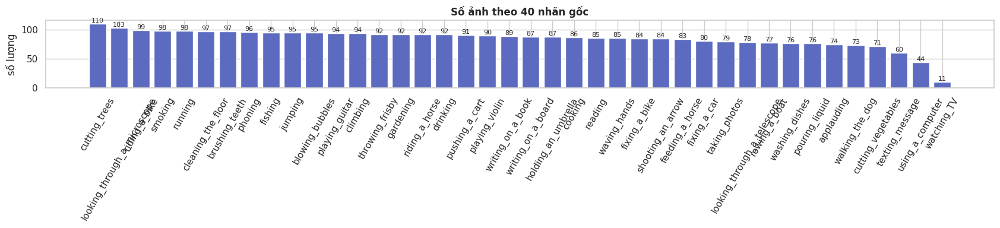

In [ ]:
ve_cot(df['original_label'], 'Số ảnh theo 40 nhãn gốc')

**Kích thước ảnh.** Model thường cần ảnh đầu vào 224×224; ảnh quá nhỏ thì phải phóng to và sẽ bị mờ.

In [ ]:
sizes = pd.DataFrame([Image.open(p).size for p in df['image_path']], columns=['width', 'height'])
print(sizes.describe().loc[['min', 'mean', 'max']])

      width  height
min   128.0   128.0
mean  128.0   128.0
max   128.0   128.0


**Xem ảnh mẫu:** mỗi nhãn 3 ảnh (mỗi cột là 1 nhãn, 10 nhãn/hình).

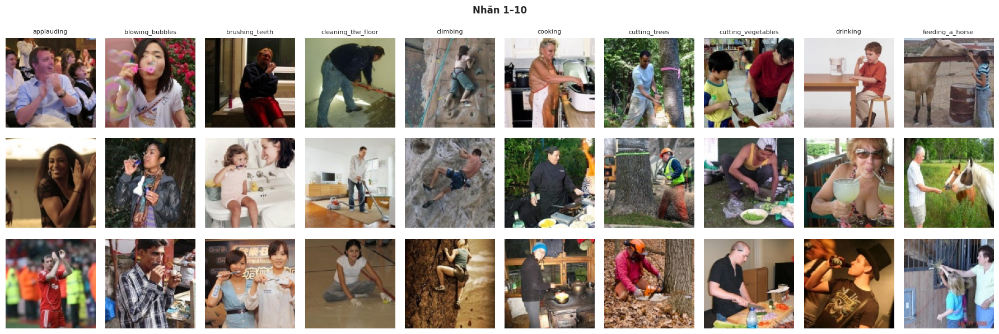

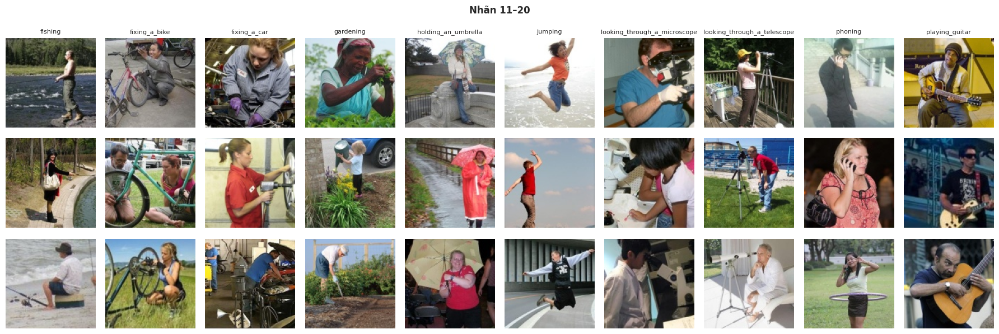

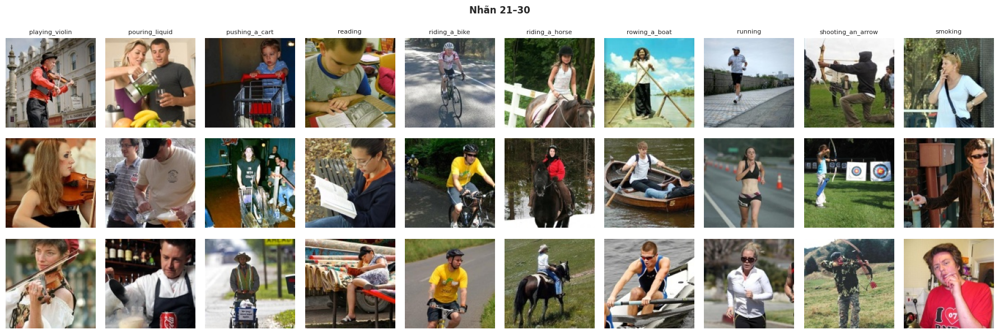

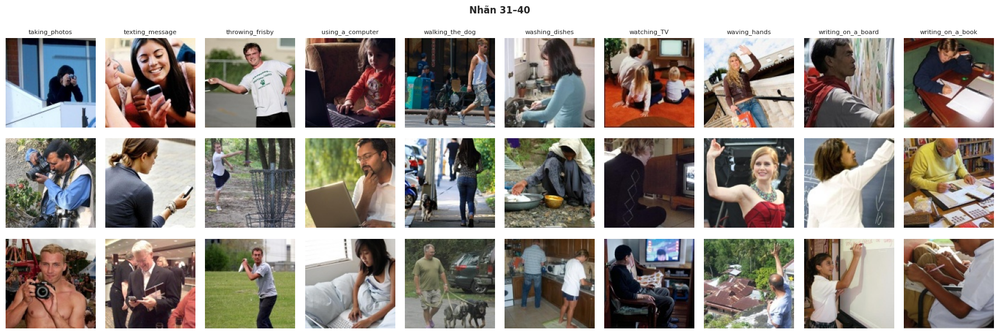

In [ ]:
labels = sorted(df['original_label'].unique())
for start in range(0, len(labels), 10):
    nhom = labels[start:start + 10]
    items = []
    for row in range(3):                      # 3 hàng
        for lbl in nhom:                      # mỗi cột = 1 nhãn
            r = df[df['original_label'] == lbl].sample(3, random_state=42).iloc[row]
            items.append({'img': r['image_path'], 'title': lbl if row == 0 else ''})
    show_grid(items, f'Nhãn {start + 1}–{start + len(nhom)}', ncols=len(nhom), size=1.8)

📝 **Nhận xét của bạn:** *(ghi lại điều bạn thấy, ví dụ: ảnh nhỏ, bị mờ, nhiều người trong ảnh…)*

📌 **Kết luận phần 1**
- 3.389 ảnh, 40 nhãn, đa số nhãn có 70–110 ảnh (khá cân bằng), trừ `watching_TV` (11), `using_a_computer` (44), `texting_message` (60).
- Tất cả ảnh 128×128, **rất nhỏ** so với 3 bộ còn lại.
- Không có bbox, nên nhãn là của **cả bức ảnh**.

## Phần 2: Map sang 6 nhãn đích

**Mục tiêu:** đổi 40 nhãn gốc thành 6 nhãn của bài toán.
**Cách làm:** viết một **bảng tra** (`dict`) *nhãn gốc → nhãn đích*. Nhãn nào không có trong bảng tra thì là `unknown`.

In [ ]:
MAPPING = {
    'phoning': 'take_on_phone',
    'texting_message': 'take_on_phone',
    'using_a_computer': 'work_on_computer',
    'riding_a_bike': 'ride',
    'riding_a_horse': 'ride',
    'rowing_a_boat': 'ride',
    'drinking': 'eat/drink',
    'pouring_liquid': 'eat/drink',
    'holding_an_umbrella': 'hold',
    'playing_guitar': 'hold',
    'playing_violin': 'hold',
    'taking_photos': 'hold',
}
df['target_label'] = df['original_label'].map(MAPPING).fillna('unknown')

# Bảng mapping đầy đủ 40 nhãn, sắp xếp theo nhãn đích
bang_map = (df.groupby(['target_label', 'original_label']).size().rename('số ảnh').reset_index()
              .sort_values(['target_label', 'số ảnh'], ascending=[True, False]))
bang_map

,target_label,original_label,số ảnh
0,eat/drink,drinking,92
1,eat/drink,pouring_liquid,76
3,hold,playing_guitar,94
4,hold,playing_violin,90
2,hold,holding_an_umbrella,87
5,hold,taking_photos,79
6,ride,riding_a_bike,99
7,ride,riding_a_horse,92
8,ride,rowing_a_boat,77
9,take_on_phone,phoning,96


,nhãn đích,số lượng,tỷ lệ %
0,unknown,2403,70.9
1,hold,350,10.3
2,ride,268,7.9
3,eat/drink,168,5.0
4,take_on_phone,156,4.6
5,work_on_computer,44,1.3


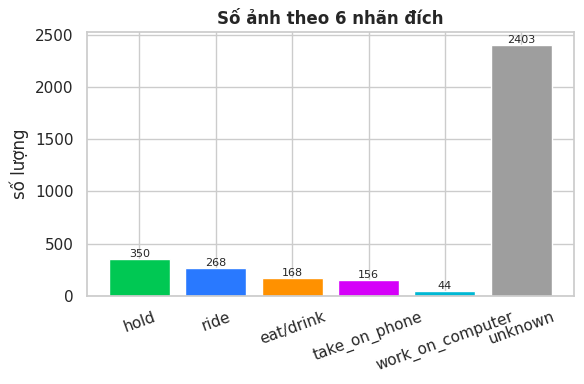

In [ ]:
display(bang_dem(df['target_label'], 'nhãn đích'))
ve_cot(df['target_label'], 'Số ảnh theo 6 nhãn đích', theo_6_lop=True, xoay=20)

**5 ảnh ngẫu nhiên cho mỗi nhãn đích** (chữ dưới ảnh là nhãn gốc):

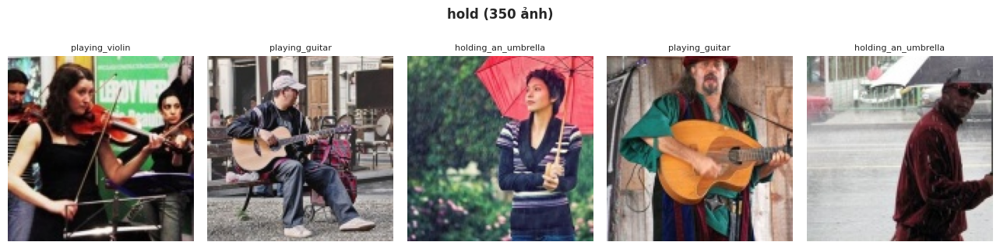

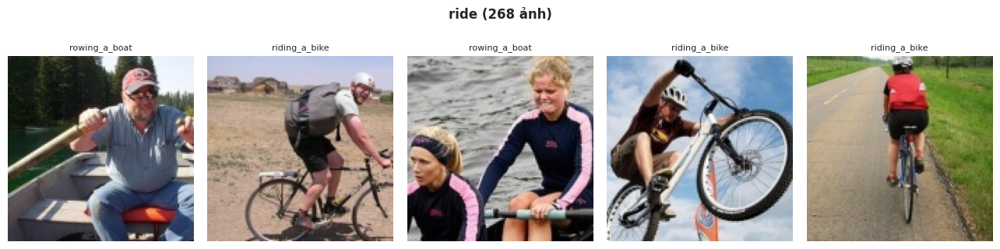

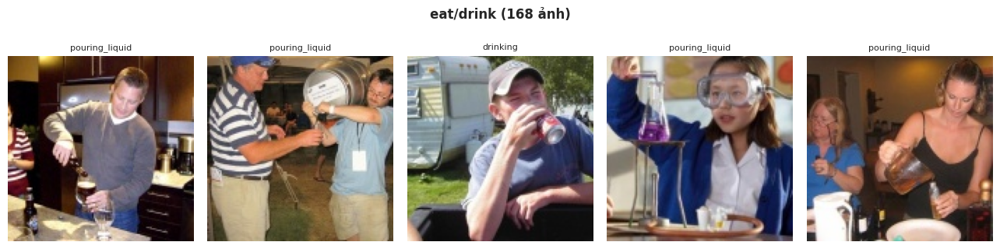

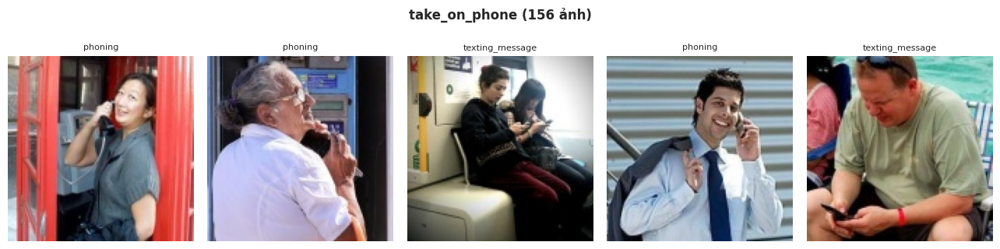

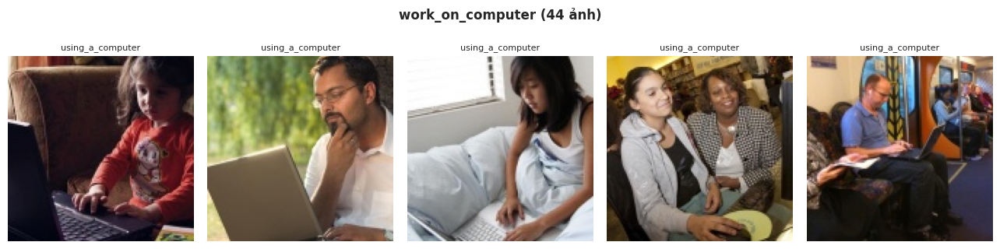

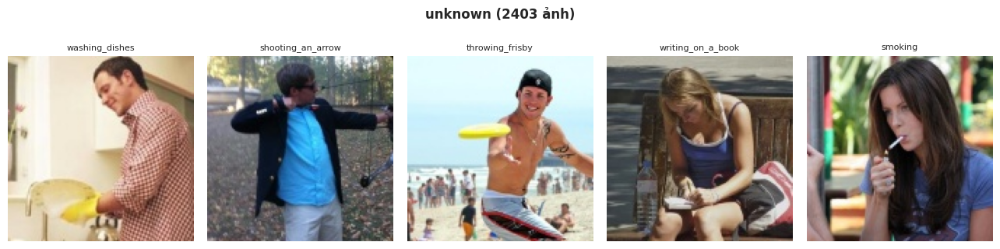

In [ ]:
for cls in TARGET_CLASSES:
    sub = df[df['target_label'] == cls]
    if len(sub) == 0:
        print(f'ℹ️ {cls}: 0 ảnh'); continue
    rows = sub.sample(min(5, len(sub)), random_state=42)
    show_grid([{'img': r.image_path, 'title': r.original_label} for r in rows.itertuples()],
              f'{cls} ({len(sub)} ảnh)', ncols=5)

**Lưu file nhãn** để dùng cho training và cho notebook tổng hợp `EDA_summary.ipynb`.
Mỗi dòng là 1 ảnh. Cột `hold_object` / `hold_verb` dùng ở phần 4.

In [ ]:
# vật thể + hành động của các nhãn gốc đang map vào hold (dùng cho phần 4)
HOLD_INFO = {
    'holding_an_umbrella': ('umbrella', 'hold'),
    'playing_guitar': ('guitar', 'play'),
    'playing_violin': ('violin', 'play'),
    'taking_photos': ('camera', 'take_photo'),
}
df['hold_object'] = df['original_label'].map(lambda l: HOLD_INFO.get(l, ('', ''))[0])
df['hold_verb'] = df['original_label'].map(lambda l: HOLD_INFO.get(l, ('', ''))[1])

df_labels = pd.DataFrame({
    'dataset': 'stanford40',
    'image': df['image_path'],
    'person_bbox': '',            # Stanford40 không có bbox
    'object_bbox': '',
    'original_label': df['original_label'],
    'target_label': df['target_label'],
    'hold_object': df['hold_object'],
    'hold_verb': df['hold_verb'],
})
print('Đã tạo df_labels:', df_labels.shape)

Đã tạo df_labels: (3389, 8)


📌 **Kết luận phần 2**
- 28/40 nhãn gốc rơi vào `unknown`, nên `unknown` chiếm khoảng 71% số ảnh.
- `work_on_computer` chỉ có 44 ảnh (1,3%), đây là lớp thiểu số nặng nhất.
- Bộ này **không có** nhãn *ăn* (eating), nên `eat/drink` chỉ có *uống* và *rót*.

## Phần 3: Những chỗ map đáng nghi

**Mục tiêu:** tìm các nhãn gốc mà việc map sang nhãn đích **có thể sai**, rồi xem ảnh để tự quyết định.
**Cách đọc:** mỗi mục có *lý do nghi ngờ*, *số ảnh bị ảnh hưởng*, và *6 ảnh* để kiểm tra. Xem xong, trả lời câu hỏi **Giữ / Bỏ / Đổi lớp?**

🔎 Chơi nhạc cụ → hold  |  184 ảnh  |  hiện đang map sang: ['hold']
   Lý do nghi ngờ: Đây là CHƠI đàn, không đơn thuần là cầm. Tư thế rất khác với cầm ô hay cầm cốc.


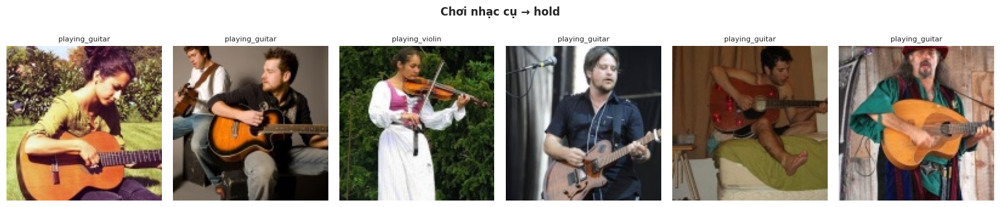

   ❓ Giữ / Bỏ / Đổi lớp?
🔎 Chụp ảnh → hold  |  79 ảnh  |  hiện đang map sang: ['hold']
   Lý do nghi ngờ: Là hành động CHỤP. Một số ảnh chụp bằng điện thoại, dễ nhầm với take_on_phone.


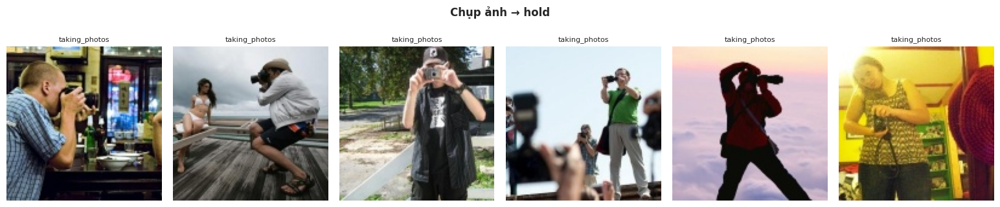

   ❓ Giữ / Bỏ / Đổi lớp?
🔎 Rót nước → eat/drink  |  76 ảnh  |  hiện đang map sang: ['eat/drink']
   Lý do nghi ngờ: Rót nước vào ly chứ không phải đang uống.


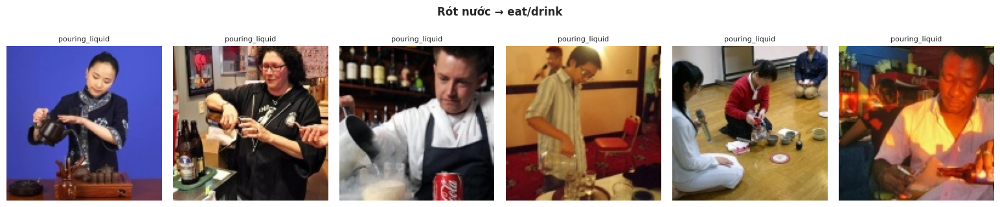

   ❓ Giữ / Bỏ / Đổi lớp?
🔎 Chèo thuyền → ride  |  77 ảnh  |  hiện đang map sang: ['ride']
   Lý do nghi ngờ: Chèo thuyền khác xa đi xe đạp/cưỡi ngựa về hình ảnh.


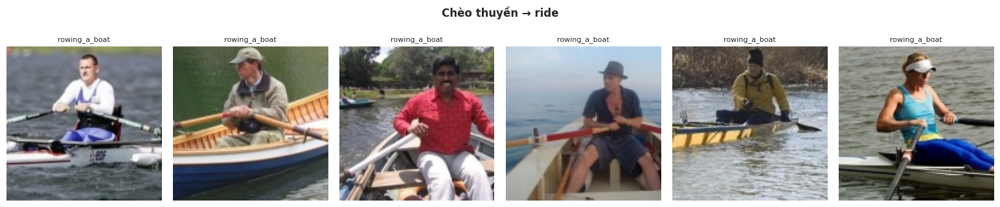

   ❓ Giữ / Bỏ / Đổi lớp?
🔎 Nhắn tin → take_on_phone  |  60 ảnh  |  hiện đang map sang: ['take_on_phone']
   Lý do nghi ngờ: Nhắn tin (nhìn màn hình) khác nghe gọi (áp tai). Cần thống nhất "take_on_phone" gồm những gì.


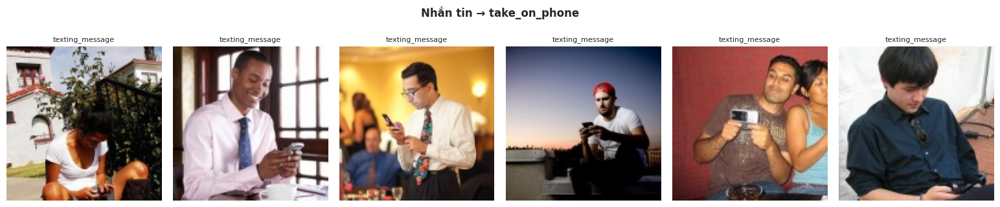

   ❓ Giữ / Bỏ / Đổi lớp?
🔎 Đang CẦM đồ vật nhưng lại là unknown  |  1346 ảnh  |  hiện đang map sang: ['unknown']
   Lý do nghi ngờ: Người trong ảnh rõ ràng đang cầm vật (sách, bút, dao, bàn chải…) nhưng bị gán unknown, trong khi cầm ô lại là hold. Model sẽ bị "rối".


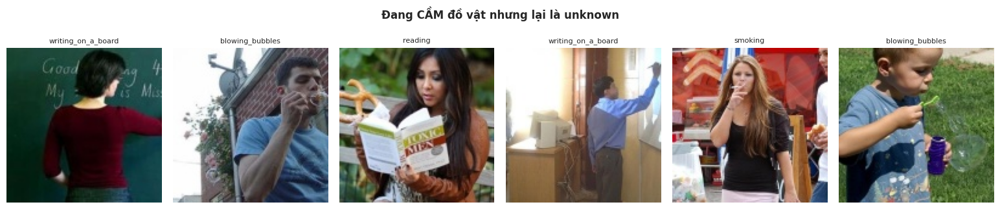

   ❓ Giữ / Bỏ / Đổi lớp?


In [ ]:
NGHI_NGO = [
    {'ten': 'Chơi nhạc cụ → hold', 'labels': ['playing_guitar', 'playing_violin'],
     'ly_do': 'Đây là CHƠI đàn, không đơn thuần là cầm. Tư thế rất khác với cầm ô hay cầm cốc.'},
    {'ten': 'Chụp ảnh → hold', 'labels': ['taking_photos'],
     'ly_do': 'Là hành động CHỤP. Một số ảnh chụp bằng điện thoại, dễ nhầm với take_on_phone.'},
    {'ten': 'Rót nước → eat/drink', 'labels': ['pouring_liquid'],
     'ly_do': 'Rót nước vào ly chứ không phải đang uống.'},
    {'ten': 'Chèo thuyền → ride', 'labels': ['rowing_a_boat'],
     'ly_do': 'Chèo thuyền khác xa đi xe đạp/cưỡi ngựa về hình ảnh.'},
    {'ten': 'Nhắn tin → take_on_phone', 'labels': ['texting_message'],
     'ly_do': 'Nhắn tin (nhìn màn hình) khác nghe gọi (áp tai). Cần thống nhất "take_on_phone" gồm những gì.'},
    {'ten': 'Đang CẦM đồ vật nhưng lại là unknown',
     'labels': ['reading', 'writing_on_a_book', 'smoking', 'brushing_teeth', 'cutting_vegetables',
                'fixing_a_bike', 'cooking', 'cleaning_the_floor', 'fishing', 'cutting_trees',
                'shooting_an_arrow', 'blowing_bubbles', 'writing_on_a_board', 'washing_dishes', 'gardening'],
     'ly_do': 'Người trong ảnh rõ ràng đang cầm vật (sách, bút, dao, bàn chải…) nhưng bị gán unknown, '
              'trong khi cầm ô lại là hold. Model sẽ bị "rối".'},
]

for ng in NGHI_NGO:
    sub = df[df['original_label'].isin(ng['labels'])]
    print('=' * 100)
    print(f"🔎 {ng['ten']}  |  {len(sub)} ảnh  |  hiện đang map sang: {sub['target_label'].unique().tolist()}")
    print(f"   Lý do nghi ngờ: {ng['ly_do']}")
    rows = sub.sample(min(6, len(sub)), random_state=1)
    show_grid([{'img': r.image_path, 'title': r.original_label} for r in rows.itertuples()], ng['ten'])
    print('   ❓ Giữ / Bỏ / Đổi lớp?')

**Nghi ngờ chung cho cả bộ: ảnh nhỏ và có nhiều người.** Stanford40 gán nhãn cho *cả ảnh*. Nếu ảnh có nhiều người, ta không biết người nào đang làm hành động. Dưới đây là ảnh gốc 128×128 hiển thị đúng kích thước thật để thấy chúng nhỏ thế nào.

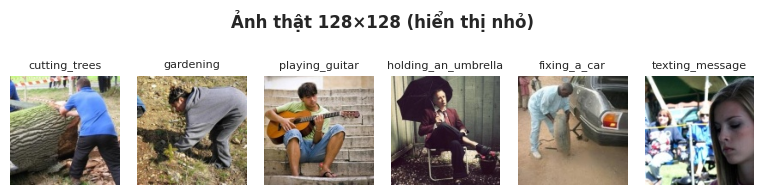

In [ ]:
rows = df.sample(6, random_state=7)
show_grid([{'img': r.image_path, 'title': f'{r.original_label}'} for r in rows.itertuples()],
          'Ảnh thật 128×128 (hiển thị nhỏ)', ncols=6, size=1.3)

📌 **Kết luận phần 3**: các quyết định cần chốt:
- Nhạc cụ / chụp ảnh: giữ trong `hold` hay chuyển `unknown`?
- `pouring_liquid`, `rowing_a_boat`: giữ hay loại khỏi tập train?
- Nhóm "đang cầm vật mà là unknown": nếu **mở rộng** `hold` để nhận chúng thì `hold` càng rộng (xem phần 4). Nếu **bỏ hẳn** những nhãn này khỏi tập train thì `unknown` sạch hơn. Nên cân nhắc **bỏ**.

## Phần 4: Lớp `hold` quá rộng: dẫn chứng và đề xuất

### 4.1 Dẫn chứng
**Mục tiêu:** đo xem lớp `hold` đang chứa bao nhiêu kiểu hành động khác nhau.
**Cách đọc:** nhiều kiểu khác nhau (vật khác, tư thế khác) nhưng chung một nhãn thì model phải học một khái niệm "cầm bất cứ thứ gì", rất khó.

In [ ]:
hold_df = df_labels[df_labels['target_label'] == 'hold']
if len(hold_df) == 0:
    print('Lớp hold không có mẫu nào trong bộ này.')
else:
    comp = bang_dem(hold_df['hold_object'].astype(str) + '  |  ' + hold_df['hold_verb'].astype(str),
                    'vật | hành động')
    print(f'Lớp hold có {len(hold_df)} mẫu, gồm {len(comp)} kiểu (vật | hành động) khác nhau')
    top5 = comp['số lượng'].head(5).sum() / len(hold_df) * 100
    print(f'Top-5 kiểu chiếm {top5:.1f}% lớp hold '
          '(càng thấp = càng phân tán = càng khó học)')
    counts = df_labels['target_label'].value_counts()
    nho_nhat = counts[counts > 0].min()
    print(f'hold gấp {counts["hold"] / nho_nhat:.1f} lần lớp nhỏ nhất ({counts.idxmin()}: {nho_nhat})')
    display(comp.head(20))

Lớp hold có 350 mẫu, gồm 4 kiểu (vật | hành động) khác nhau
Top-5 kiểu chiếm 100.0% lớp hold (càng thấp = càng phân tán = càng khó học)
hold gấp 8.0 lần lớp nhỏ nhất (work_on_computer: 44)


,vật | hành động,số lượng,tỷ lệ %
0,guitar | play,94,26.9
1,violin | play,90,25.7
2,umbrella | hold,87,24.9
3,camera | take_photo,79,22.6


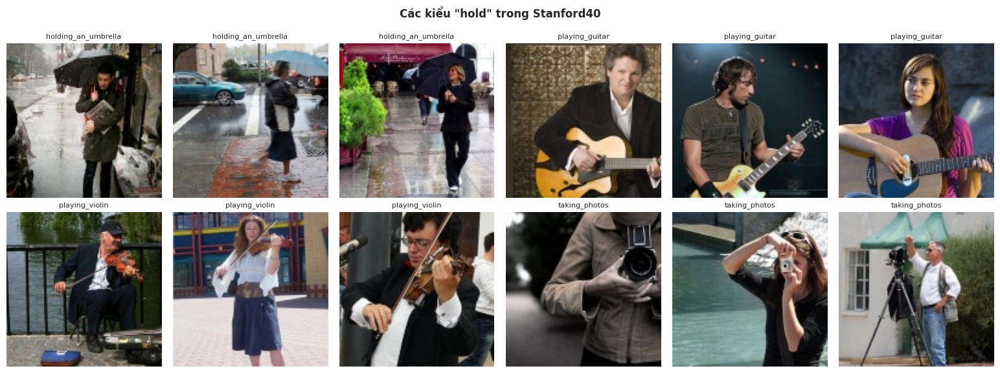

In [ ]:
# 3 ảnh cho mỗi kiểu trong hold: nhìn xem chúng khác nhau thế nào
items = []
for lbl in HOLD_INFO:
    for r in df[df['original_label'] == lbl].sample(3, random_state=3).itertuples():
        items.append({'img': r.image_path, 'title': lbl})
show_grid(items, 'Các kiểu "hold" trong Stanford40', ncols=6)

### 4.2 Ba phương án giới hạn `hold`

| Phương án | Ý tưởng | Đổi nhãn? |
|---|---|---|
| **A. Theo vật thể** | Chỉ giữ `hold` khi vật là **đồ nhỏ cầm tay** (danh sách `HOLD_OBJECTS` bên dưới). Nhạc cụ, ván trượt, vợt, gậy, diều… chuyển sang `unknown` | Có |
| **B. Theo động từ** | Chỉ giữ `hold` khi hành động đúng là **cầm/mang** (`hold`, `carry`). Các hành động "chơi", "chụp", "vung"… chuyển sang `unknown` | Có |
| **C. Cắt số lượng** | Giữ nguyên định nghĩa, chỉ **bớt mẫu `hold`** khi training (tối đa `k` lần lớp nhỏ nhất) | Không, chỉ đổi cách lấy mẫu |

👉 **Khuyến nghị mặc định: A + B**, tức `hold` = *cầm hoặc mang một vật nhỏ bằng tay*. Định nghĩa hẹp và rõ thì model dễ học hơn. **C** để dành cho lúc training (dùng sampler), không dùng để sửa nhãn.

Bạn đổi phương án bằng biến `HOLD_POLICY` ở cell dưới: `None`, `'A'`, `'B'`, `'A+B'`.

In [ ]:
HOLD_POLICY = 'A+B'   # 👈 đổi ở đây: None | 'A' | 'B' | 'A+B'

# Đồ vật nhỏ cầm tay (tên theo kiểu COCO, dùng dấu gạch dưới)
HOLD_OBJECTS = {
    'cup', 'bottle', 'wine_glass', 'bowl', 'umbrella', 'handbag', 'backpack', 'suitcase', 'tie',
    'book', 'knife', 'fork', 'spoon', 'scissors', 'remote', 'toothbrush', 'hair_drier',
    'teddy_bear', 'vase', 'camera', 'clock', 'banana', 'apple', 'orange', 'sandwich',
    'hot_dog', 'pizza', 'donut', 'cake', 'carrot', 'broccoli',
}
HOLD_VERBS = {'hold', 'carry'}


def gioi_han_hold(row, policy=HOLD_POLICY):
    """Trả về nhãn mới sau khi áp phương án giới hạn hold cho 1 dòng."""
    lbl = row['target_label']
    if lbl != 'hold' or policy is None:
        return lbl
    obj = str(row.get('hold_object', '')).replace(' ', '_')
    verb = str(row.get('hold_verb', ''))
    if 'A' in policy and obj not in HOLD_OBJECTS:
        return 'unknown'
    if 'B' in policy and verb not in HOLD_VERBS:
        return 'unknown'
    return lbl


def so_sanh_phuong_an(df):
    """Bảng số mẫu 6 lớp: trước và sau từng phương án A, B, A+B, và C (k=3)."""
    out = pd.DataFrame(index=TARGET_CLASSES)
    out['hiện tại'] = df['target_label'].value_counts().reindex(TARGET_CLASSES, fill_value=0)
    for p in ['A', 'B', 'A+B']:
        out[p] = df.apply(lambda r: gioi_han_hold(r, p), axis=1).value_counts().reindex(TARGET_CLASSES, fill_value=0)
    nho_nhat = out['hiện tại'][out['hiện tại'] > 0].min()
    out['C (k=3)'] = out['hiện tại']
    out.loc['hold', 'C (k=3)'] = min(out.loc['hold', 'hiện tại'], 3 * nho_nhat)
    return out

,hiện tại,A,B,A+B,C (k=3)
hold,350,166,87,87,132
ride,268,268,268,268,268
eat/drink,168,168,168,168,168
take_on_phone,156,156,156,156,156
work_on_computer,44,44,44,44,44
unknown,2403,2587,2666,2666,2403


Phương án A+B: 263 ảnh bị đẩy ra khỏi hold


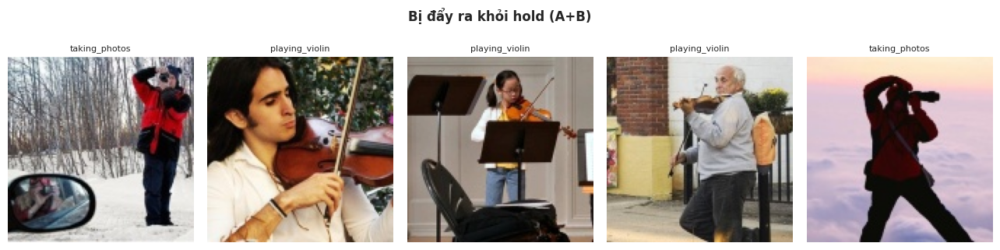

In [ ]:
display(so_sanh_phuong_an(df_labels))
df_labels['target_label_hold_limited'] = df_labels.apply(gioi_han_hold, axis=1)

# 5 ảnh ví dụ bị đẩy ra khỏi hold với phương án đang chọn
bi_day = df_labels[(df_labels['target_label'] == 'hold') & (df_labels['target_label_hold_limited'] != 'hold')]
print(f'Phương án {HOLD_POLICY}: {len(bi_day)} ảnh bị đẩy ra khỏi hold')
show_grid([{'img': r.image, 'title': r.original_label} for r in bi_day.sample(min(5, len(bi_day)), random_state=0).itertuples()],
          f'Bị đẩy ra khỏi hold ({HOLD_POLICY})', ncols=5)

In [ ]:
df_labels.to_csv('labels_6class_stanford40.csv', index=False)
print('💾 Đã lưu labels_6class_stanford40.csv', df_labels.shape)

💾 Đã lưu labels_6class_stanford40.csv (3389, 9)


📌 **Kết luận phần 4**
- Trong Stanford40, `hold` gồm 4 kiểu rất khác nhau (ô, đàn guitar, đàn violin, máy ảnh), chỉ `holding_an_umbrella` là **cầm** đúng nghĩa.
- Với **A+B**, `hold` chỉ còn ảnh cầm ô. Stanford40 gần như **không đóng góp** cho `hold`; dữ liệu `hold` nên lấy chủ yếu từ V-COCO và HICO-DET.
- File `labels_6class_stanford40.csv` có cả nhãn cũ (`target_label`) và nhãn đã giới hạn (`target_label_hold_limited`) để so sánh khi training.